### Import necessary packages

In [1]:
import muspan as ms
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
import os 

### Select directories for csv files and saving created domains

In [ ]:
csv_directory = r".\Template_CSV-Files"
saving_domain_directory = r".\Template_Generated-Domains"

if not os.path.exists(saving_domain_directory):
    os.makedirs(saving_domain_directory)

### Create domains with data from the csv-files

In [3]:
csvs = os.listdir(csv_directory)

domains = []

# Change the name of the X and Y coordinates based on the columns in the csv file
x_label_name = "Cell X Position"
y_label_name = "Cell Y Position"
# For this example, the class_name is created more generally so it can be used for the updating of colours and visualisation further down
class_name = "Phenotype"

for i, csv in enumerate(csvs):
    csv_path = os.path.join(csv_directory,csv)

    df = pd.read_csv(csv_path)

    points = np.asarray([df[x_label_name], df[y_label_name]])
    points[1,:] = -points[1,:]
    domain = ms.domain(str(csv))
    domain.add_points(points.T, "Cell centres")

    # Add information from the csv file 
    # input will be (name_of_label_in_domain, df[name_of_label_in_csv])
    class_name = "Phenotype"
    domain.add_labels("Phenotype", df["Phenotype"])
    domain.add_labels("ROI", df["Parent"])
    domain.add_labels("CD8 intensity", df["CD8..Cell..Mean"], cmap="viridis")
    domain.add_labels("PDPN intensity", df["PDPN..Cell..Mean"], cmap="viridis")
    domain.add_labels("aSMA intensity", df["aSMA..Cell..Mean"], cmap="viridis")
    domain.add_labels("PDGFRa intensity", df["PDGFRa..Cell..Mean"], cmap="viridis")
    domain.add_labels("FAP intensity", df["FAP..Cell..Mean"], cmap="viridis")
    domain.add_labels("panCK intensity", df["panCK..Cell..Mean"], cmap="viridis")
    
    domains.append(domain)
    
    ms.io.save_domain(domain, path_to_save=saving_domain_directory, name_of_file= str(csv))

Domain test_data_1.csv saved successfully to .\Template_Generated-Domains.
Domain test_data_2.csv saved successfully to .\Template_Generated-Domains.
Domain test_data_3.csv saved successfully to .\Template_Generated-Domains.


### Optional - Update Colours of Labels

In [7]:
# Choose colours from https://matplotlib.org/3.1.1/gallery/color/named_colors.html

# Create a dictionary with the label category as key and the desired colour as value

phenotype_colors = {
    'CD8' : 'cyan', 'CD8_Other': 'darkturquoise', 'PDPN_CD8' : 'cadetblue', 'PDPN_CD8_Other': 'darkcyan',
                        'FAP':'red', 'FAP_PDGFRa':'mediumvioletred', 'FAP_PDGFRa_aSMA':'violet', 'FAP_PDPN': 'darkviolet',
                   'FAP_PDPN_PDGFRa':'orchid', 'FAP_PDPN_PDGFRa_aSMA':'thistle', 'FAP_PDPN_aSMA':'mediumslateblue', 'FAP_aSMA': 'magenta',
                   'PDGFRa': 'yellow', 'PDGFRa_aSMA': 'khaki', 'PDPN': 'orange', 'PDPN_PDGFRa': 'gold', 'PDPN_PDGFRa_aSMA': 'goldenrod', 'PDPN_aSMA' : 'orangered','aSMA' : 'forestgreen',
                    'panCK' : 'whitesmoke', 'panCK_Other': 'lightgrey','FAP_PDPN_panCK': 'lavender','FAP_panCK': 'palevioletred', 'PDPN_panCK': 'peachpuff', 'PDPN_panCK_Other': 'wheat', 'Other': 'black',  'unclassified detections': 'grey'
}

# Adjust with label_name should be updated with the specified colours
for domain in domains:
    domain.update_colors(new_colors=phenotype_colors, colors_to_update="labels", label_name=class_name)

    # Save domains again with updated colours
    ms.io.save_domain(domain, path_to_save=saving_domain_directory, name_of_file= str(domain.name))

Domain test_data_1.csv saved successfully to .\Template_Generated-Domains.
Domain test_data_2.csv saved successfully to .\Template_Generated-Domains.
Domain test_data_3.csv saved successfully to .\Template_Generated-Domains.


### Visualise a domain

(<Figure size 800x500 with 2 Axes>, <Axes: >)

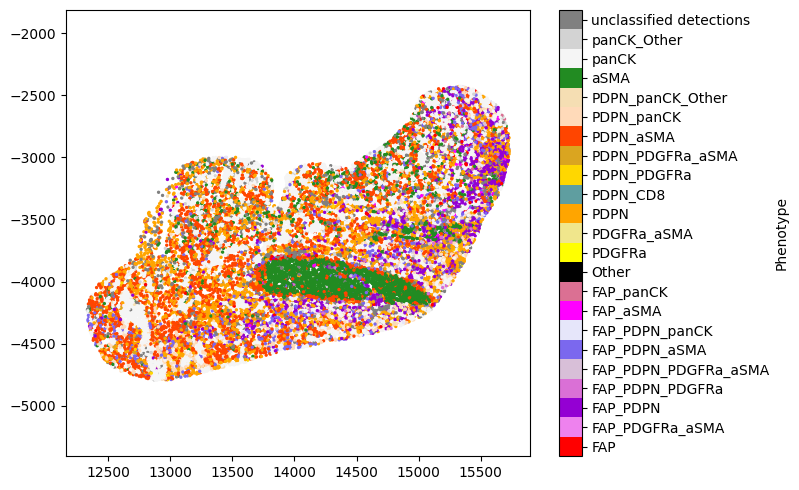

In [11]:
# Choose which domain to visualise
domain =  domains[1]

plt.figure(figsize=(8,5))

ms.visualise.visualise(domain, color_by=class_name, 
                       ax=plt.gca(),  
                       marker_size= 2,
                       objects_to_plot = ("ROI", "ROI 1")
                       )